In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("/content/diabetes.csv")

data.head()

In [2]:
data.shape

(768, 9)

In [3]:
data.columns.to_list()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

In [4]:
data.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [10]:
data.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [7]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
x = data.drop(columns='Outcome', axis=1)
y = data['Outcome']
x.shape

(768, 8)

**Feature variables**


*   Pregnancies : Number of times pregnant
*   Glucose: Glucose concentraion which is a direct diabetes
*   Blood Pressure: Monitors cardiovascular and metabolic health
*   Skin thickness : Estimates subcutaneous body fat

*   Insulin : Assess insulin resistance and secretion
*   BMI : measures overall body mass and obesity levels
*   DiabetesPedigreeFunction : Heraditory risk
*   Age : Patient's age

**Target Variable**

*   Outcome : Binary output with 0 and 1. 0 indicates No diabetes and 1 indicates Diabetes diagnosed











In [13]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.85)
print(x_train.shape)
print(x_test.shape)
cat_columns = x_train.select_dtypes(include='object').columns.to_list()
print("Categorical columns:",cat_columns)

(652, 8)
(116, 8)
Categorical columns: []


In [17]:
#There are no missing values in the dataset, still verifying
train_medians = x_train.median()
x_train = x_train.fillna(train_medians)
x_test = x_test.fillna(train_medians)
print("Missing values",x_train.isna().sum().sum())

Missing values 0


In [19]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
feature_names = x.columns
x_train = pd.DataFrame(x_train, columns=feature_names)
x_test = pd.DataFrame(x_test, columns=feature_names)
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.892166,1.198586,-0.776853,0.707070,0.843537,-0.194365,0.332002,0.468718
1,0.012591,-1.114300,-0.572924,0.083579,-0.280577,-0.534486,-0.500670,-0.466631
2,-0.573793,-1.145139,-0.980781,0.145928,-0.039695,-0.206963,1.454042,-1.061853
3,0.012591,-0.127469,-0.267031,0.395324,0.352852,0.145755,-0.725078,-0.806758
4,-1.160176,1.352778,1.058506,0.769420,5.348913,2.551791,-0.143389,-0.891790


In [22]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train,y_train)

In [ ]:
#Why Logistic Regression?


Logistic Regression is the standard algorithm for clinical diagnostic data classification.
It is appropriate because


1.   Logistic Regression outputs a continuous probablility score between 0 and 1.
2.  The probability of having diabetes can be used for suggesting actions like follow-up lab tests and other procedures
3. Logistic Regression trains and makes predictions fastly with low memory. So that it can be used with low resource devices and can be associated with existing clinical systems
4. It is simpler and avoids overfitting
5. Every feature gets a weight, so it is easy to point on why the prediction was made


In [28]:
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,confusion_matrix)
y_pred=model.predict(x_train)
print("Accuracy Score:",accuracy_score(y_train,y_pred))
print("Precision Score:",precision_score(y_train,y_pred))
print("Recall Score:",recall_score(y_train,y_pred))
print("F1 Score:",f1_score(y_train,y_pred))


Accuracy Score: 0.7806748466257669
Precision Score: 0.7403314917127072
Recall Score: 0.5826086956521739
F1 Score: 0.6520681265206812


In [29]:
#test accuracy
y_pred=model.predict(x_test)
print("Accuracy Score:",accuracy_score(y_test,y_pred))
print("Precision Score:",precision_score(y_test,y_pred))
print("Recall Score:",recall_score(y_test,y_pred))
print("F1 Score:",f1_score(y_test,y_pred))

Accuracy Score: 0.7672413793103449
Precision Score: 0.7037037037037037
Recall Score: 0.5
F1 Score: 0.5846153846153846


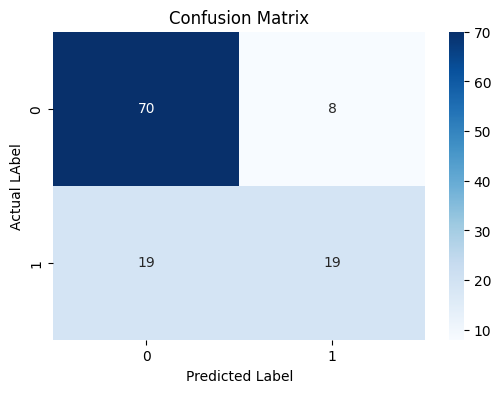

In [26]:
confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt='d',cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual LAbel')
plt.show()

**Interpretation of model results**


1.   Strong negative identification : Model performs well at identifying healthy individuals

2.   False negatives : A recall of 50% means half of the diabetic patients are missed under standard probability decision thershold

3. The calssification decision threshold can be lowered to capture more true positive diabetes cases and can lower false negatives


---

